# Lecture 2 — Class Exercise
# Bar Charts: World Happiness Report 2023

---

> **Your task:** Create **2 polished bar charts** using the World Happiness Report dataset.  
> **Push to:** `week02/lecture02_exercise.ipynb` in **your own GitHub repo** before the end of class.

---

### Rules to keep in mind 💡
1. Every bar chart **must have a zero baseline** — no exceptions
2. Every chart **must have an insight title**, not a topic title
3. Aim for **professional quality** — clean background, readable font, no clutter
4. Horizontal bars for long category names

---


## Setup — Run this cell first


In [1]:
import pandas as pd
import numpy as np

# World Happiness Report 2023 — representative data
# Source: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2023

df = pd.read_csv('../data/world_happiness_2023.csv')
df.columns = ['Country','Region','Happiness_Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']


print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
df.head()


Dataset: 63 countries, 9 columns


,Country,Region,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Corruption
0,Finland,Western Europe,7.804,10.775,0.954,71.9,0.949,0.142,0.179
1,Denmark,Western Europe,7.586,10.933,0.954,72.7,0.931,0.168,0.234
2,Iceland,Western Europe,7.525,10.878,0.983,72.5,0.961,0.260,0.150
3,Israel,Middle East and North Africa,7.473,10.527,0.916,72.4,0.903,0.149,0.826
4,Netherlands,Western Europe,7.464,11.015,0.939,72.4,0.879,0.240,0.296


In [2]:
import plotly.express as px
import plotly.graph_objects as go

# Explore the dataset before you start
print("Regions in dataset:")
print(df['Region'].value_counts())
print("\nScore range:", df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())
print("\nBottom 10 countries:")
print(df.nsmallest(10, 'Happiness_Score')[['Country','Region','Happiness_Score']])


Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range: 1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

---
## Task 1 — Regional Comparison Bar Chart

**What to build:** A horizontal bar chart showing the **average happiness score by region**, sorted from highest to lowest.

**Requirements:**
- Horizontal orientation (category names are long)
- Sorted by score, descending (so the happiest region is at the top)
- Zero baseline on x-axis
- At least one design choice that goes beyond the Plotly default (colour, annotation, labels, etc.)
- An insight title that answers: *which region stands out and why does it matter?*

**Hint:** Use `df.groupby('Region')['Happiness_Score'].mean()` to compute the averages.


                         Region  Happiness_Score
5                    South Asia         3.618250
7            Sub-Saharan Africa         4.064714
3  Middle East and North Africa         4.943333
6                Southeast Asia         5.695250
2   Latin America and Caribbean         5.699000
1                     East Asia         5.966000
0    Central and Eastern Europe         6.338143
4         North America and ANZ         7.018250
8                Western Europe         7.085533


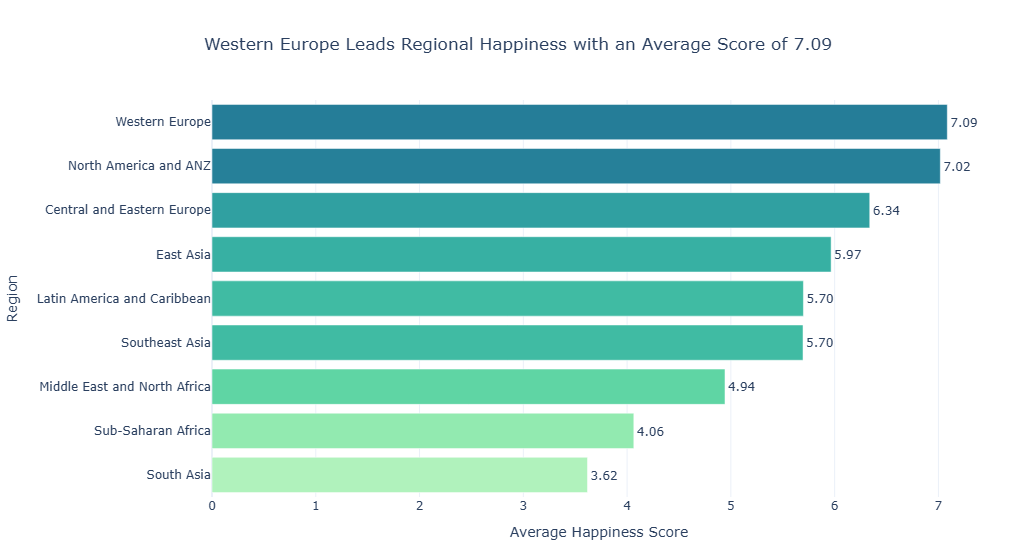

In [4]:
# Task 1: Regional comparison bar chart
# -------------------------------------

# Step 1: Compute average happiness score by region
region_avg = (df.groupby('Region')['Happiness_Score']
              .mean()
              .reset_index()
              .sort_values('Happiness_Score'))  # sort for horizontal bar

print(region_avg)

# Step 2: Build your chart
# YOUR CODE HERE
# Step 2: Build your chart

import plotly.express as px

# Find the region with the highest average happiness score
top_region = region_avg.iloc[-1]['Region']
top_score = region_avg.iloc[-1]['Happiness_Score']

fig = px.bar(
    region_avg,
    x='Happiness_Score',
    y='Region',
    orientation='h',
    color='Happiness_Score',
    color_continuous_scale='Tealgrn',
    text='Happiness_Score',
    labels={
        'Happiness_Score': 'Average Happiness Score',
        'Region': 'Region'
    },
    title=(
        f'{top_region} Leads Regional Happiness '
        f'with an Average Score of {top_score:.2f}'
    )
)

# Put the highest-scoring region at the top
fig.update_yaxes(autorange=True)

# Display score labels and ensure the x-axis starts at zero
fig.update_traces(
    texttemplate='%{text:.2f}',
    textposition='outside'
)

fig.update_xaxes(rangemode='tozero')

# Improve the chart's appearance
fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    height=550,
    margin=dict(l=150, r=50, t=100, b=50),
    coloraxis_showscale=False
)

fig.show()



---
## Task 2 — Bottom vs. Top: A Contrast Story

**What to build:** A bar chart that highlights the **gap between the happiest and least happy countries**, focusing on a specific insight.

**Requirements:**
- Show the **top 8 AND bottom 8 countries** together (16 bars total)
- Use **colour** to distinguish the two groups (not Plotly's default rainbow)
- Add a **visual separator or annotation** that emphasises the gap
- Insight title that tells the story of the gap

**Hint:** Use `pd.concat([df.nlargest(8,'Happiness_Score'), df.nsmallest(8,'Happiness_Score')])` to get both groups.

**Stretch goal:** Add a vertical reference line showing the global average.


Global average: 5.81
Global average happiness score: 5.81
Gap between the two groups: 3.13 points


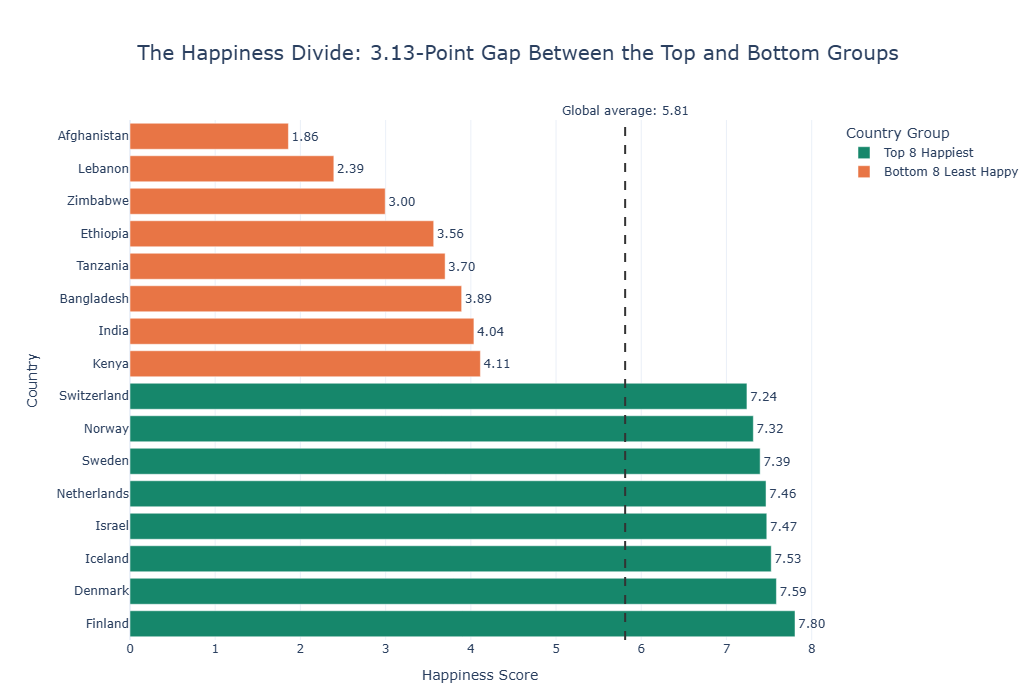

In [5]:
# Task 2: Top 8 vs. Bottom 8 contrast
# ------------------------------------

# Step 1: Get top and bottom countries
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'
bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score')
global_avg = df['Happiness_Score'].mean()
print(f"Global average: {global_avg:.2f}")

# Step 2: Build your chart
# YOUR CODE HERE
# Task 2: Bottom vs. Top — A Contrast Story

# Step 1: Select the 8 happiest and 8 least happy countries
top8 = df.nlargest(8, 'Happiness_Score').copy()
bottom8 = df.nsmallest(8, 'Happiness_Score').copy()

# Give each group a label
top8['Group'] = 'Top 8 Happiest'
bottom8['Group'] = 'Bottom 8 Least Happy'

# Step 2: Combine the two groups
contrast_df = pd.concat([top8, bottom8], ignore_index=True)

# Step 3: Sort from highest to lowest
contrast_df = contrast_df.sort_values(
    'Happiness_Score', ascending=False
)

# Step 4: Calculate the global average and the gap
global_avg = df['Happiness_Score'].mean()
lowest_top = top8['Happiness_Score'].min()
highest_bottom = bottom8['Happiness_Score'].max()
gap = lowest_top - highest_bottom

print(f"Global average happiness score: {global_avg:.2f}")
print(f"Gap between the two groups: {gap:.2f} points")

# Step 5: Create the chart
import plotly.express as px

fig = px.bar(
    contrast_df,
    x='Happiness_Score',
    y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={
        'Top 8 Happiest': '#16876B',
        'Bottom 8 Least Happy': '#E87545'
    },
    text='Happiness_Score',
    labels={
        'Happiness_Score': 'Happiness Score',
        'Country': 'Country',
        'Group': 'Country Group'
    },
    title=(
        f'The Happiness Divide: {gap:.2f}-Point Gap '
        'Between the Top and Bottom Groups'
    )
)

# Put the highest-scoring country at the top
fig.update_yaxes(autorange=True)

# Display scores on the bars
fig.update_traces(
    texttemplate='%{text:.2f}',
    textposition='outside'
)

# Add the global average reference line
fig.add_vline(
    x=global_avg,
    line_dash='dash',
    line_color='#333333',
    line_width=2,
    annotation_text=f'Global average: {global_avg:.2f}',
    annotation_position='top'
)

# Add professional styling
fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    title_font_size=20,
    height=700,
    margin=dict(l=130, r=70, t=120, b=60),
    legend_title_text='Country Group'
)

fig.update_xaxes(rangemode='tozero')

fig.show()



---
## Done? Stretch Goal

If you finish both tasks with time to spare, try this:

**Task 3 (stretch):** Build a **grouped bar chart** comparing 2 sub-factors (e.g. `GDP_per_capita` and `Freedom`) across the 5 most populated regions. Use colour meaningfully and write an insight title.

Regions to include: `'Western Europe'`, `'Latin America'`, `'East Asia'`, `'Sub-Saharan Africa'`, `'South Asia'`


,Region,GDP,Freedom
0,Western Europe,10.963533,0.896067
1,Latin America and Caribbean,9.134923,0.754231
2,East Asia,10.312000,0.754000
3,Sub-Saharan Africa,7.082000,0.599429
4,South Asia,7.152250,0.546250


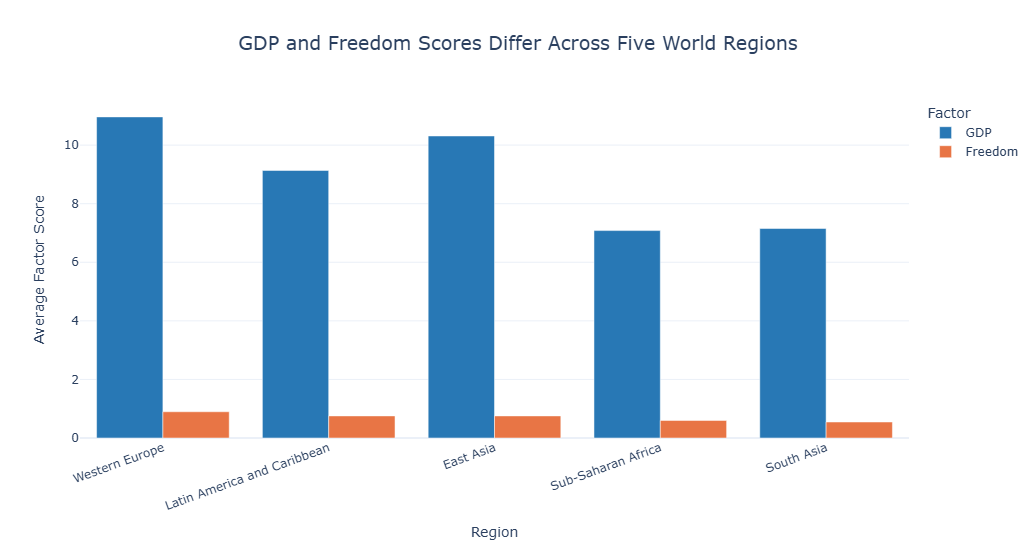

In [10]:
# Stretch goal — grouped bar chart
# YOUR CODE HERE
# Task 3: Grouped bar chart comparing GDP per capita and Freedom

# Task 3: Compare GDP and Freedom across five regions

import pandas as pd
import plotly.express as px

# Step 1: Select the five required regions
regions = [
    'Western Europe',
    'Latin America and Caribbean',
    'East Asia',
    'Sub-Saharan Africa',
    'South Asia'
]

region_df = df[df['Region'].isin(regions)].copy()

# Step 2: Calculate average GDP and Freedom by region
factor_avg = (
    region_df.groupby('Region')[['GDP', 'Freedom']]
    .mean()
    .reindex(regions)
    .reset_index()
)

display(factor_avg)

# Step 3: Reshape the data for a grouped bar chart
factor_long = factor_avg.melt(
    id_vars='Region',
    value_vars=['GDP', 'Freedom'],
    var_name='Factor',
    value_name='Average Score'
)

# Step 4: Create the chart
fig = px.bar(
    factor_long,
    x='Region',
    y='Average Score',
    color='Factor',
    barmode='group',
    color_discrete_map={
        'GDP': '#2878B5',
        'Freedom': '#E87545'
    },
    labels={
        'Region': 'Region',
        'Average Score': 'Average Factor Score',
        'Factor': 'Factor'
    },
    title='GDP and Freedom Scores Differ Across Five World Regions'
)

# Step 5: Style the chart
fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    title_font_size=19,
    height=550,
    xaxis_tickangle=-20,
    legend_title_text='Factor'
)

fig.show()



In [7]:
print(df.columns.tolist())


['Country', 'Region', 'Happiness_Score', 'GDP', 'Social_Support', 'Life_Expectancy', 'Freedom', 'Generosity', 'Corruption']


In [9]:
print(df['Region'].unique())

<StringArray>
[              'Western Europe', 'Middle East and North Africa',
        'North America and ANZ',   'Central and Eastern Europe',
  'Latin America and Caribbean',                    'East Asia',
               'Southeast Asia',                   'South Asia',
           'Sub-Saharan Africa']
Length: 9, dtype: str
